In [1]:
!pip install --no-index --find-links=/kaggle/input/datasets/malihealavi/pydicom-packages-rsna-breast-cancer pylibjpeg pylibjpeg-libjpeg

Looking in links: /kaggle/input/datasets/malihealavi/pydicom-packages-rsna-breast-cancer
Processing /kaggle/input/datasets/malihealavi/pydicom-packages-rsna-breast-cancer/pylibjpeg-2.1.0-py3-none-any.whl
Processing /kaggle/input/datasets/malihealavi/pydicom-packages-rsna-breast-cancer/pylibjpeg_libjpeg-2.4.0-cp312-cp312-manylinux2014_x86_64.manylinux_2_17_x86_64.whl


In [2]:

import warnings
warnings.filterwarnings("ignore")
import os
import sys 
import json
from glob import glob
import random
import collections
import time
import re
from typing import Optional

import numpy as np
import pandas as pd
import pydicom
from pydicom.pixel_data_handlers.util import apply_voi_lut
import cv2
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import StratifiedKFold
from IPython.display import clear_output
clear_output()


site_id - ID code for the source hospital.

patient_id - ID code for the patient.

image_id - ID code for the image.

laterality - Whether the image is of the left or right breast.

view - The orientation of the image. The default for a screening exam is to capture two views per breast.

age - The patient's age in years.

implant - Whether or not the patient had breast implants. Site 1 only provides breast implant information at the patient level, not at the breast level.

density - A rating for how dense the breast tissue is, with A being the least dense and D being the most dense. Extremely dense tissue can make diagnosis more difficult. Only provided for train.

machine_id - An ID code for the imaging device.

cancer - Whether or not the breast was positive for malignant cancer. The target value. Only provided for train.

biopsy - Whether or not a follow-up biopsy was performed on the breast. Only provided for train.

invasive - If the breast is positive for cancer, whether or not the cancer proved to be invasive. Only provided for train.

BIRADS - 0 if the breast required follow-up, 1 if the breast was rated as negative for cancer, and 2 if the breast was rated as normal. Only provided for train.

prediction_id - The ID for the matching submission row. Multiple images will share the same prediction ID. Test only.

difficult_negative_case - True if the case was unusually difficult. Only provided for train.

In [3]:
train = pd.read_csv('/kaggle/input/competitions/rsna-breast-cancer-detection/train.csv')
train['patient_id'] = train['patient_id'].astype(str)
train

,site_id,patient_id,image_id,laterality,view,age,cancer,biopsy,invasive,BIRADS,implant,density,machine_id,difficult_negative_case
0,2,10006,462822612,L,CC,61.0,0,0,0,NaN,0,NaN,29,False
1,2,10006,1459541791,L,MLO,61.0,0,0,0,NaN,0,NaN,29,False
2,2,10006,1864590858,R,MLO,61.0,0,0,0,NaN,0,NaN,29,False
3,2,10006,1874946579,R,CC,61.0,0,0,0,NaN,0,NaN,29,False
4,2,10011,220375232,L,CC,55.0,0,0,0,0.0,0,NaN,21,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
54701,1,9973,1729524723,R,MLO,43.0,0,0,0,1.0,0,C,49,False
54702,1,9989,63473691,L,MLO,60.0,0,0,0,NaN,0,C,216,False
54703,1,9989,1078943060,L,CC,60.0,0,0,0,NaN,0,C,216,False
54704,1,9989,398038886,R,MLO,60.0,0,0,0,0.0,0,C,216,True


In [4]:
# Count the number of unique cancer labels for each patient's breast
breast_target_variance = train.groupby(['patient_id', 'laterality'])['cancer'].nunique()

# Find cases where the unique count is greater than 1
mismatched_breasts = breast_target_variance[breast_target_variance > 1]

print(f"Total breasts with various labels across views: {len(mismatched_breasts)}")

if len(mismatched_breasts) > 0:
    print("\nSample of breasts with mismatched labels:")
    print(mismatched_breasts.head())

Total breasts with various labels across views: 0


In [5]:
train['cancer'].value_counts()


cancer
0    53548
1     1158
Name: count, dtype: int64

In [6]:
patient_targets = train.groupby('patient_id')['cancer'].apply(list)


filtered_patients = patient_targets[
    patient_targets.apply(lambda x: (0 in x and 1 in x) or all(val == 1 for val in x))
]

# 3. If you need the original rows for these patients
filtered_df = train[train['patient_id'].isin(filtered_patients.index)]

print(f"Number of patients haaving cancer: {len(filtered_patients)} among all {len(patient_targets)} patients")

Number of patients haaving cancer: 486 among all 11913 patients


In [7]:
print (f'list of patients with canecr in both laterality')
cancer_both_lateral=patient_targets[
    patient_targets.apply(lambda x:  all(val == 1 for val in x))
]
print(cancer_both_lateral)
train[train['patient_id'].isin(['16518' , '1759', '31964', '45137', '54463', '6654'])]

list of patients with canecr in both laterality
patient_id
16518    [1, 1, 1, 1]
1759     [1, 1, 1, 1]
31964    [1, 1, 1, 1]
45137    [1, 1, 1, 1]
54463    [1, 1, 1, 1]
6654     [1, 1, 1, 1]
Name: cancer, dtype: object


,site_id,patient_id,image_id,laterality,view,age,cancer,biopsy,invasive,BIRADS,implant,density,machine_id,difficult_negative_case
6006,2,16518,442815464,L,MLO,51.0,1,1,1,NaN,0,NaN,48,False
6007,2,16518,914043890,L,CC,51.0,1,1,1,NaN,0,NaN,48,False
6008,2,16518,1464760605,R,CC,51.0,1,1,1,NaN,0,NaN,48,False
6009,2,16518,1531151973,R,MLO,51.0,1,1,1,NaN,0,NaN,48,False
7081,2,1759,1211304263,L,CC,70.0,1,1,1,NaN,0,NaN,29,False
7082,2,1759,1811195939,L,MLO,70.0,1,1,1,NaN,0,NaN,29,False
7083,2,1759,276588619,R,CC,70.0,1,1,1,NaN,0,NaN,29,False
7084,2,1759,1005049159,R,MLO,70.0,1,1,1,NaN,0,NaN,29,False
20724,2,31964,488598184,L,CC,50.0,1,1,1,NaN,0,NaN,48,False
20725,2,31964,1352530320,L,MLO,50.0,1,1,1,NaN,0,NaN,48,False


In [8]:
test = pd.read_csv('/kaggle/input/competitions/rsna-breast-cancer-detection/test.csv')
test

,site_id,patient_id,image_id,laterality,view,age,implant,machine_id,prediction_id
0,2,10008,736471439,L,MLO,81,0,21,10008_L
1,2,10008,1591370361,L,CC,81,0,21,10008_L
2,2,10008,68070693,R,MLO,81,0,21,10008_R
3,2,10008,361203119,R,CC,81,0,21,10008_R


In [9]:
submission = pd.read_csv('/kaggle/input/competitions/rsna-breast-cancer-detection/sample_submission.csv')
submission

,prediction_id,cancer
0,10008_L,0.021168
1,10008_R,0.021168


In [10]:
for col in train.columns:
    print(f'{col} : {train[col].nunique()}')

site_id : 2
patient_id : 11913
image_id : 54706
laterality : 2
view : 6
age : 63
cancer : 2
biopsy : 2
invasive : 2
BIRADS : 3
implant : 2
density : 4
machine_id : 10
difficult_negative_case : 2


In [11]:
cat_cols = ['site_id', 'laterality', 'view',
       'cancer', 'biopsy', 'invasive', 'BIRADS', 'implant', 'density',
       'machine_id', 'difficult_negative_case']
for col in cat_cols:
    print(f'{col} : {train[col].unique()}')
    

site_id : [2 1]
laterality : ['L' 'R']
view : ['CC' 'MLO' 'ML' 'LM' 'AT' 'LMO']
cancer : [0 1]
biopsy : [0 1]
invasive : [0 1]
BIRADS : [nan  0.  1.  2.]
implant : [0 1]
density : [nan 'C' 'D' 'B' 'A']
machine_id : [ 29  21 216  93  49  48 170 210 190 197]
difficult_negative_case : [False  True]


In [12]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 54706 entries, 0 to 54705
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   site_id                  54706 non-null  int64  
 1   patient_id               54706 non-null  object 
 2   image_id                 54706 non-null  int64  
 3   laterality               54706 non-null  object 
 4   view                     54706 non-null  object 
 5   age                      54669 non-null  float64
 6   cancer                   54706 non-null  int64  
 7   biopsy                   54706 non-null  int64  
 8   invasive                 54706 non-null  int64  
 9   BIRADS                   26286 non-null  float64
 10  implant                  54706 non-null  int64  
 11  density                  29470 non-null  object 
 12  machine_id               54706 non-null  int64  
 13  difficult_negative_case  54706 non-null  bool   
dtypes: bool(1), float64(2)

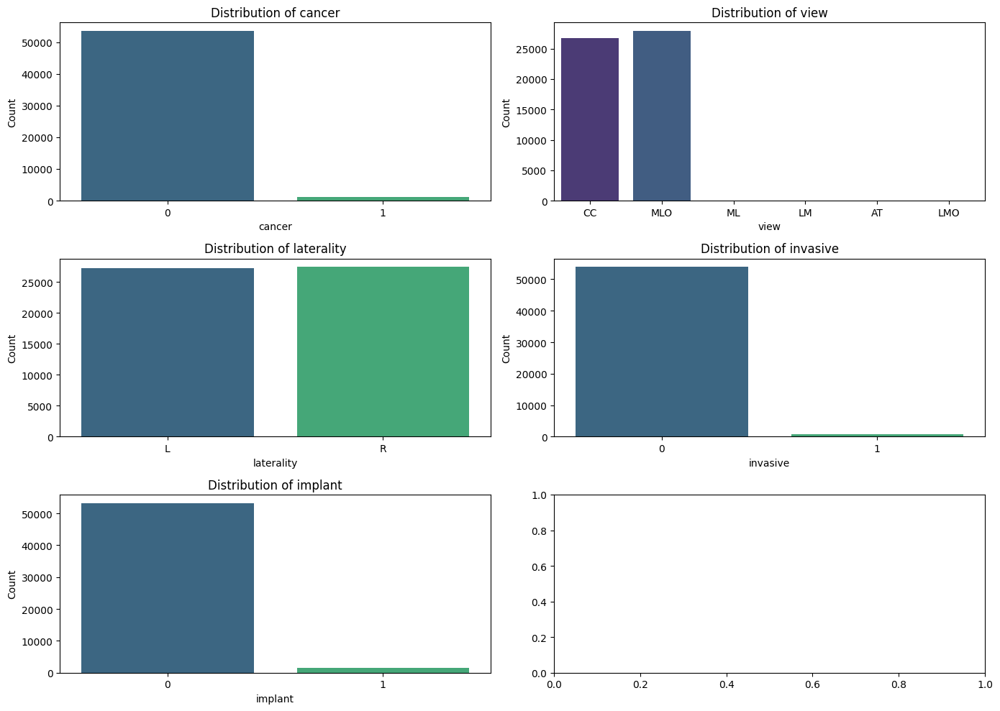

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

# Define the list of categorical columns to plot
cat_cols = ['cancer', 'view', 'laterality', 'invasive' , 'implant' , ]

# Set up the figure with subplots
fig, axes = plt.subplots(3, 2, figsize=(14, 10))
axes = axes.flatten()

# Iterate and plot
for i, col in enumerate(cat_cols):
    sns.countplot(data=train, x=col, ax=axes[i], palette='viridis')
    axes[i].set_title(f'Distribution of {col}')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Count')

plt.tight_layout()
plt.show()

## age - cancer

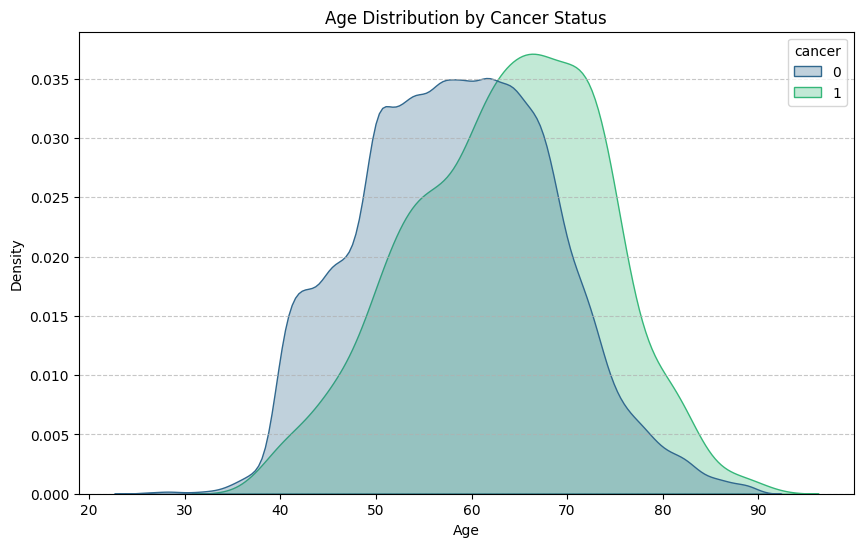

In [14]:

# Plotting the age distribution by cancer status
plt.figure(figsize=(10, 6))
sns.kdeplot(data=train, x='age', hue='cancer', fill=True, common_norm=False, palette='viridis', alpha=0.3)

plt.title('Age Distribution by Cancer Status')
plt.xlabel('Age')
plt.ylabel('Density')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.savefig('age_distribution_kde.png')

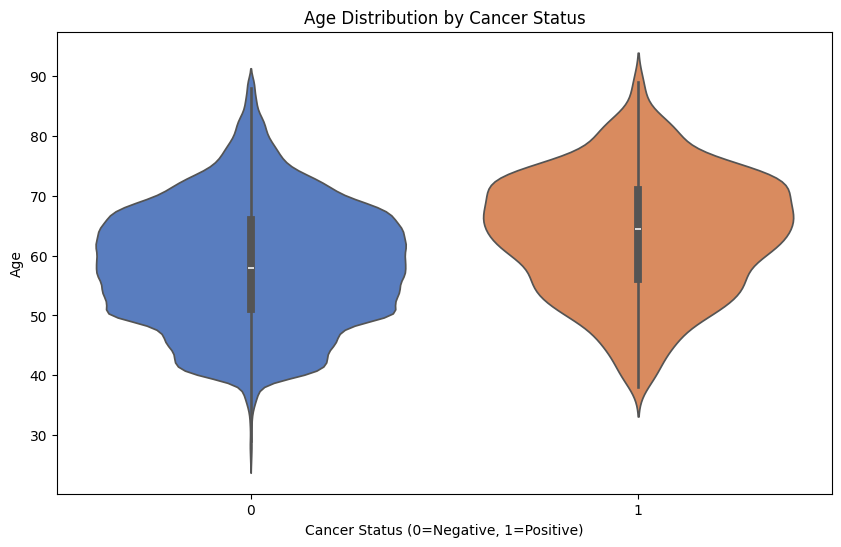

In [15]:
plt.figure(figsize=(10, 6))
sns.violinplot(data=train, x='cancer', y='age', palette='muted')

plt.title('Age Distribution by Cancer Status')
plt.xlabel('Cancer Status (0=Negative, 1=Positive)')
plt.ylabel('Age')
plt.savefig('age_distribution_violin.png')

## Laterality - Cancer 

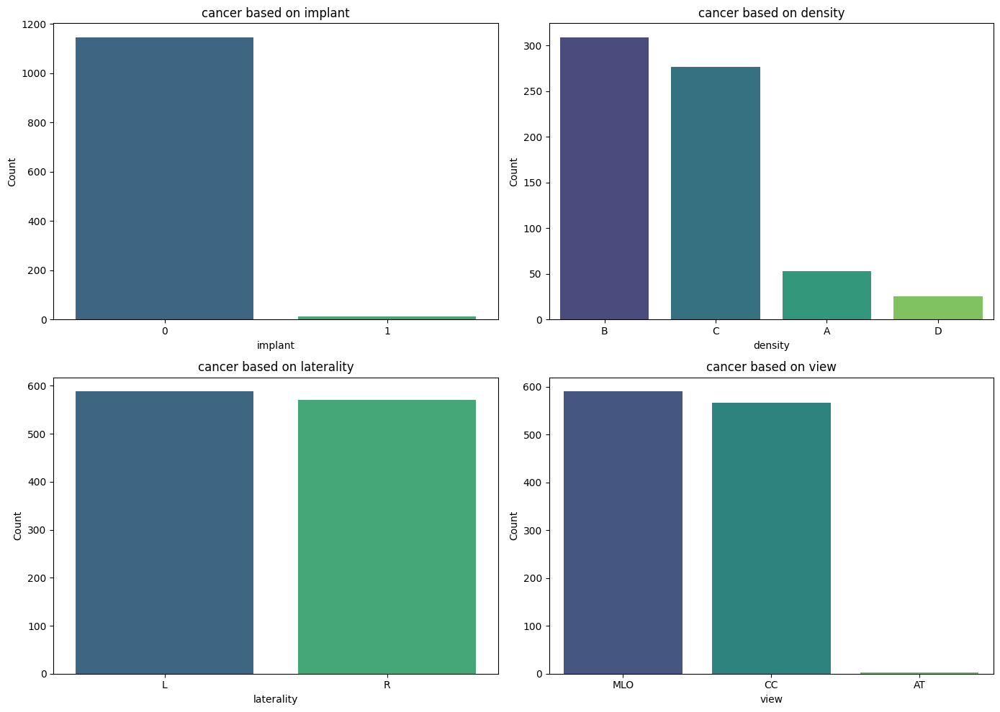

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

train_df = pd.read_csv('/kaggle/input/competitions/rsna-breast-cancer-detection/train.csv')
train_df['patient_laterality_cancer'] = train_df.groupby(['patient_id', 'laterality'])['cancer'].transform('max')

df=train_df[train_df['patient_laterality_cancer'] == 1]

cat_cols = ['implant' , 'density' , 'laterality' , 'view']
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

# Iterate and plot
for i, col in enumerate(cat_cols):
    sns.countplot(data=df, x=col, ax=axes[i], palette='viridis')
    axes[i].set_title(f'cancer based on {col}')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Count')

plt.tight_layout()
plt.show()

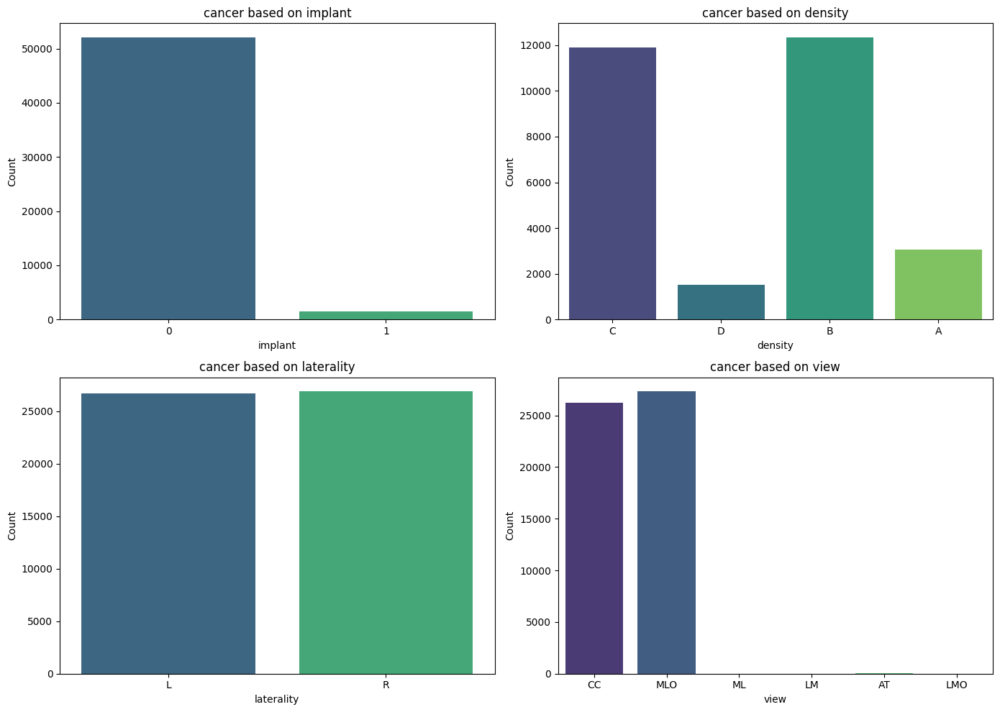

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

train_df = pd.read_csv('/kaggle/input/competitions/rsna-breast-cancer-detection/train.csv')
train_df['patient_laterality_cancer'] = train_df.groupby(['patient_id', 'laterality'])['cancer'].transform('max')

df=train_df[train_df['patient_laterality_cancer'] == 0]

cat_cols = ['implant' , 'density' , 'laterality' , 'view']
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

# Iterate and plot
for i, col in enumerate(cat_cols):
    sns.countplot(data=df, x=col, ax=axes[i], palette='viridis')
    axes[i].set_title(f'cancer based on {col}')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Count')

plt.tight_layout()
plt.show()

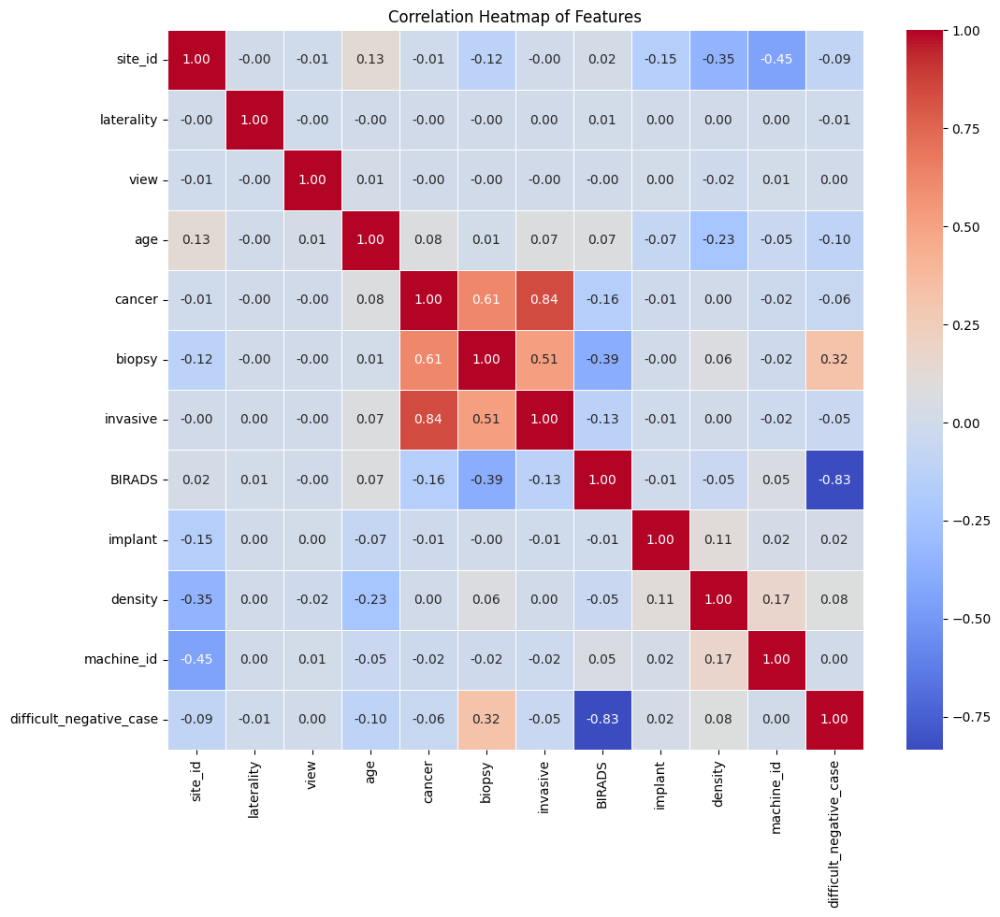

In [18]:

df = train
# 1. Fill missing values (Crucial step before encoding)
# Using mode to fill categorical NaNs
df['BIRADS'] = df['BIRADS'].fillna(df['BIRADS'].mode()[0])
df['density'] = df['density'].fillna(df['density'].mode()[0])

# 2. Encode categorical columns
# We create a copy to keep original text data intact if needed
df_encoded = df.copy()
categorical_cols = [ 'laterality', 'view', 'density', ]

# Apply LabelEncoder to all categorical columns
for col in categorical_cols:
    le = LabelEncoder()
    df_encoded[col] = le.fit_transform(df_encoded[col].astype(str))
cols = ['site_id', 'laterality', 'view', 'age',
       'cancer', 'biopsy', 'invasive', 'BIRADS', 'implant', 'density',
       'machine_id', 'difficult_negative_case']
# 3. Calculate Correlation
correlation_matrix = df_encoded[cols].corr()

# 4. Plot Heatmap
plt.figure(figsize=(12, 10))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Correlation Heatmap of Features')
plt.show()

## Dicom

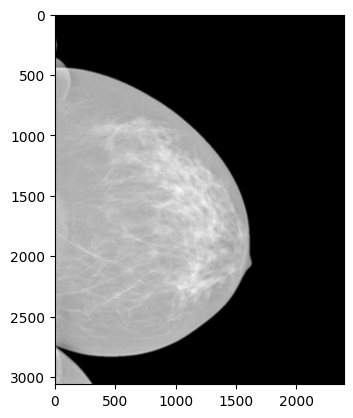

In [19]:
path = '/kaggle/input/competitions/rsna-breast-cancer-detection/train_images/10042/102733848.dcm'
img = pydicom.dcmread(path).pixel_array
plt.imshow(img, cmap='gray')
plt.show()

In [20]:
path = '/kaggle/input/competitions/rsna-breast-cancer-detection/train_images/10042/102733848.dcm'
img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
img == None

True

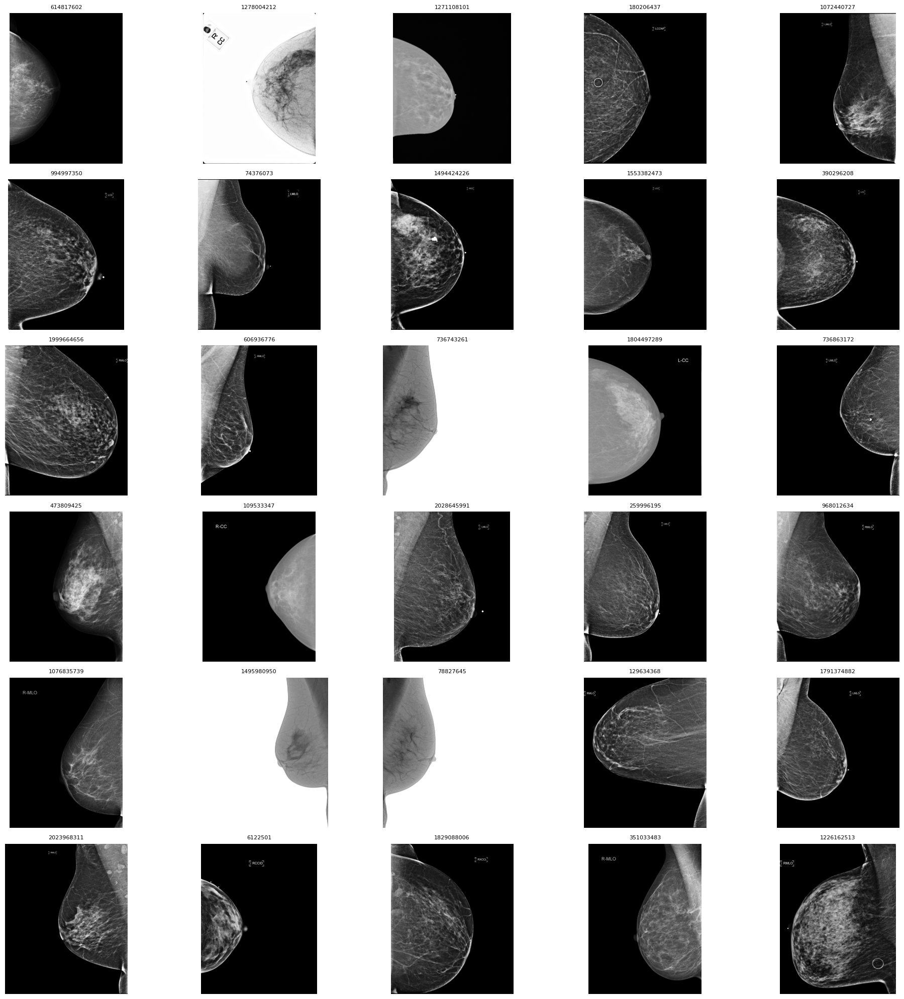

In [21]:
train_img = sorted(glob("/kaggle/input/competitions/rsna-breast-cancer-detection/train_images/*/*.dcm"))
random_img = random.sample(train_img, k=30)

fig, axes = plt.subplots(6, 5, figsize=(20, 20))
axes = axes.flatten()

for i, path in enumerate(random_img):
    img = pydicom.dcmread(path).pixel_array
    axes[i].imshow(img, cmap='gray')
    axes[i].axis('off')
    axes[i].set_title(path.split('/')[-1].replace('.dcm', ''), fontsize=8)

plt.tight_layout()
plt.show()

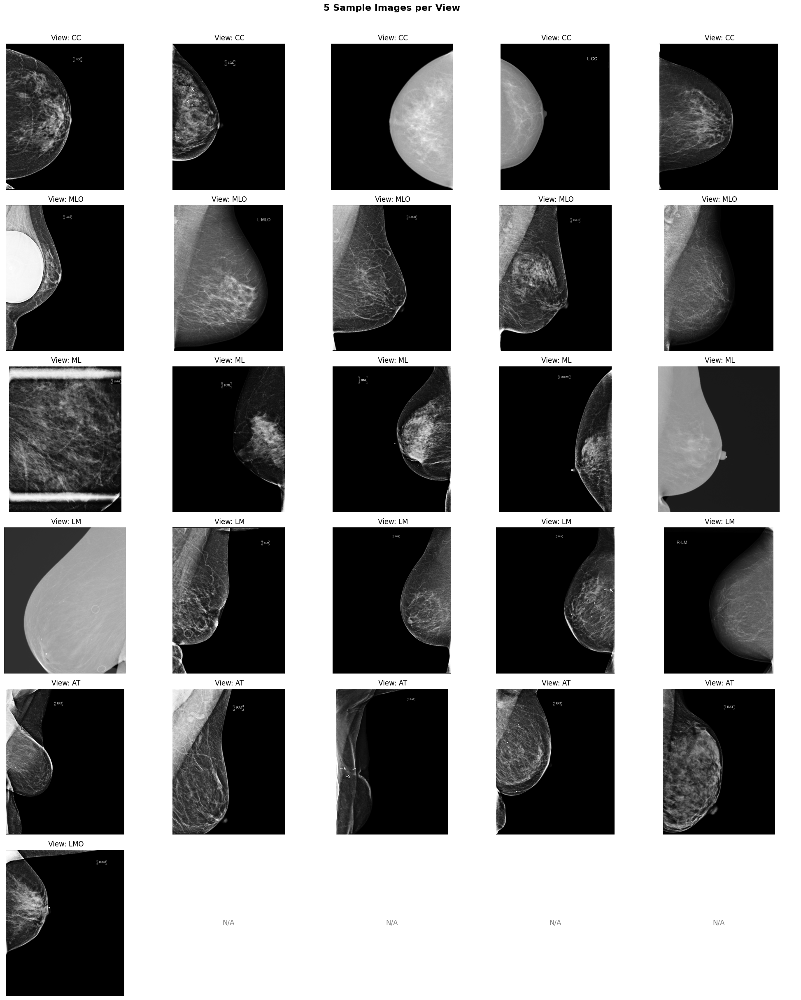

In [22]:
df = train
views = df['view'].unique()
cols = 5

fig, axes = plt.subplots(len(views), cols, figsize=(20, 4 * len(views)))

for row_idx, view in enumerate(views):
    view_df = df[df['view'] == view]
    samples = view_df.sample(min(cols, len(view_df)), random_state=42)
    
    for col_idx in range(cols):
        ax = axes[row_idx, col_idx]
        
        if col_idx < len(samples):
            row = samples.iloc[col_idx]
            path = f"/kaggle/input/competitions/rsna-breast-cancer-detection/train_images/{row['patient_id']}/{row['image_id']}.dcm"
            
            try:
                img = pydicom.dcmread(path).pixel_array
                ax.imshow(img, cmap='gray')
                ax.set_title(f" View: {row['view']}", fontsize=12)
            except Exception as e:
                ax.text(0.5, 0.5, f'Error\n{str(e)[:30]}', ha='center', va='center', transform=ax.transAxes)
        else:
            ax.text(0.5, 0.5, 'N/A', ha='center', va='center', 
                    transform=ax.transAxes, fontsize=12, color='gray')
        
        # Label the leftmost column with the view name
        if col_idx == 0:
            ax.set_ylabel(view, fontsize=13, fontweight='bold', rotation=0, 
                         labelpad=60, va='center')
        ax.axis('off')

plt.suptitle('5 Sample Images per View', fontsize=16, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

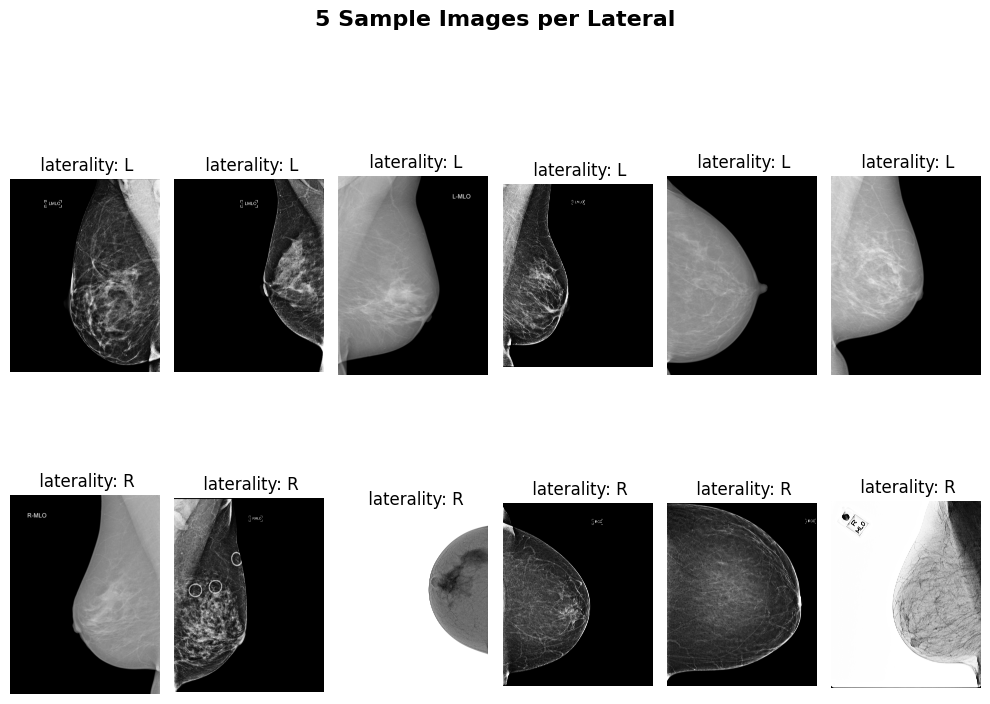

In [23]:
df = train
lats = df['laterality'].unique()
cols = 6

fig, axes = plt.subplots(len(lats), cols, figsize=(10, 4 * len(lats)))

for row_idx, lat in enumerate(lats):
    view_df = df[df['laterality'] == lat]
    samples = view_df.sample(min(cols, len(view_df)))
    
    for col_idx in range(cols):
        ax = axes[row_idx, col_idx]
        
        if col_idx < len(samples):
            row = samples.iloc[col_idx]
            path = f"/kaggle/input/competitions/rsna-breast-cancer-detection/train_images/{row['patient_id']}/{row['image_id']}.dcm"
            
            try:
                img = pydicom.dcmread(path).pixel_array
                ax.imshow(img, cmap='gray')
                ax.set_title(f" laterality: {row['laterality']}", fontsize=12)
            except Exception as e:
                ax.text(0.5, 0.5, f'Error\n{str(e)[:30]}', ha='center', va='center', transform=ax.transAxes)
        else:
            ax.text(0.5, 0.5, 'N/A', ha='center', va='center', 
                    transform=ax.transAxes, fontsize=12, color='gray')
        
        # Label the leftmost column with the view name
        if col_idx == 0:
            ax.set_ylabel(view, fontsize=13, fontweight='bold', rotation=0, 
                         labelpad=60, va='center')
        ax.axis('off')

    plt.suptitle('5 Sample Images per Lateral', fontsize=16, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

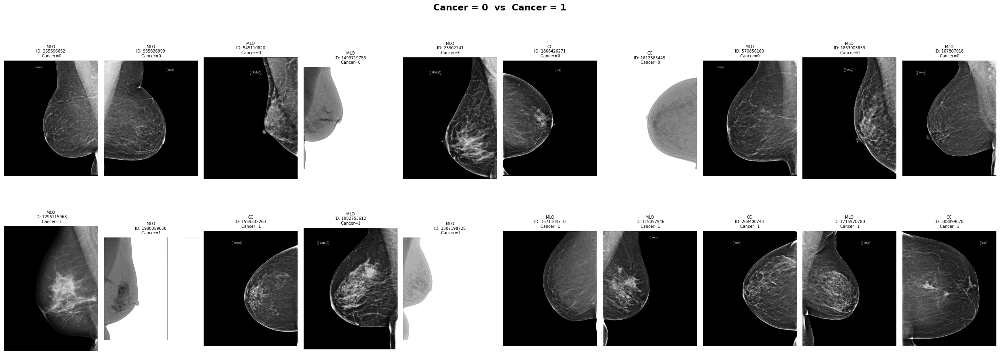

In [24]:
n = 10
cancer_0 = df[df['cancer'] == 0].sample(n, random_state=42)
cancer_1 = df[df['cancer'] == 1].sample(min(n, (df['cancer'] == 1).sum()), random_state=42)

fig, axes = plt.subplots(2, n, figsize=(25, 10))

for col_idx, (label, samples) in enumerate([(0, cancer_0), (1, cancer_1)]):
    for col in range(n):
        ax = axes[label, col]

        if col < len(samples):
            row = samples.iloc[col]
            path = f"/kaggle/input/competitions/rsna-breast-cancer-detection/train_images/{row['patient_id']}/{row['image_id']}.dcm"
            try:
                img = pydicom.dcmread(path).pixel_array
                ax.imshow(img, cmap='gray')
                ax.set_title(f"{row['view']}\nID: {row['image_id']}\n Cancer={row['cancer']}", fontsize=7)
            except Exception as e:
                ax.text(0.5, 0.5, f'Error\n{str(e)[:30]}', ha='center', va='center', transform=ax.transAxes)
        else:
            ax.text(0.5, 0.5, 'N/A', ha='center', va='center',
                    transform=ax.transAxes, fontsize=12, color='gray')

        if col == 0:
            color = 'green' if label == 0 else 'red'
            ax.set_ylabel(f'Cancer = {label}', fontsize=13, fontweight='bold',
                          rotation=0, labelpad=70, va='center', color=color)
        ax.axis('off')

plt.suptitle('Cancer = 0  vs  Cancer = 1', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

In [25]:
import pandas as pd
from sklearn.model_selection import StratifiedGroupKFold

df = train
# 1. Generate a single 'Ground Truth' target per unique patient using max aggregation
patient_targets = df.groupby('patient_id')['cancer'].max().reset_index()
patient_targets.rename(columns={'cancer': 'patient_cancer'}, inplace=True)

# 2. Merge this patient-level label back into your main row-level dataframe
df = df.merge(patient_targets, on='patient_id', how='left')

# 3. Initialize StratifiedGroupKFold
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)

# 4. Map rows to their corresponding fold assignment
df['fold'] = -1
for fold, (train_idx, val_idx) in enumerate(sgkf.split(X=df, y=df['patient_cancer'], groups=df['patient_id'])):
    df.loc[val_idx, 'fold'] = fold

# Verification check
for fold_num in range(5):
    fold_df = df[df['fold'] == fold_num]
    print(f"Fold {fold_num}: Rows = {len(fold_df)}, "
          f"Unique Patients = {fold_df['patient_id'].nunique()}, "
          f"Patient Cancer Rate = {fold_df['patient_cancer'].mean():.4f},"
          f"target Cancer Rate = {fold_df['cancer'].mean():.4f}"
            )

Fold 0: Rows = 10958, Unique Patients = 2382, Patient Cancer Rate = 0.0430,target Cancer Rate = 0.0215
Fold 1: Rows = 10890, Unique Patients = 2383, Patient Cancer Rate = 0.0421,target Cancer Rate = 0.0218
Fold 2: Rows = 10908, Unique Patients = 2382, Patient Cancer Rate = 0.0400,target Cancer Rate = 0.0201
Fold 3: Rows = 11011, Unique Patients = 2383, Patient Cancer Rate = 0.0446,target Cancer Rate = 0.0228
Fold 4: Rows = 10939, Unique Patients = 2383, Patient Cancer Rate = 0.0388,target Cancer Rate = 0.0197


In [26]:
import pandas as pd
import random

def create_balanced_patient_subset(df, random_seed=42):
    """
    Subsamples a dataframe to have an equal number of positive and negative patients,
    retaining all associated image rows for the selected patients.
    """
    # 1. Generate the patient-level ground truth label using maximum aggregation
    # If any view is a 1, the patient becomes a 1.
    patient_targets = df.groupby('patient_id')['cancer'].max()
    
    # 2. Isolate the patient IDs by their aggregated class
    pos_patient_ids = patient_targets[patient_targets == 1].index.tolist()
    neg_patient_ids = patient_targets[patient_targets == 0].index.tolist()
    
    # 3. Randomly sample the negative patients to match the exact count of positive patients
    random.seed(random_seed)
    sampled_neg_patient_ids = random.sample(neg_patient_ids, len(pos_patient_ids))
    
    # 4. Combine the balanced lists of patient IDs
    balanced_patient_ids = pos_patient_ids + sampled_neg_patient_ids
    
    # 5. Filter the original dataframe to extract all rows belonging to these specific patients
    balanced_df = df[df['patient_id'].isin(balanced_patient_ids)].copy()
    
    return balanced_df

# --- Execution ---
# Assume 'raw_df' is your loaded dataframe
balanced_df = create_balanced_patient_subset(df)

# --- Verification ---
print(f"Total Rows in Subset: {len(balanced_df)}")
print(f"Total Unique Patients: {balanced_df['patient_id'].nunique()}")
print(f"Patient-Level Target Distribution:\n{balanced_df.groupby('patient_id')['cancer'].max().value_counts()}")
balanced_df['cancer'].value_counts()

Total Rows in Subset: 4510
Total Unique Patients: 972
Patient-Level Target Distribution:
cancer
0    486
1    486
Name: count, dtype: int64


cancer
0    3352
1    1158
Name: count, dtype: int64

In [27]:
res = train.groupby(['patient_id', 'laterality']).agg({
        'image_id': list,
        'view': list,
        'cancer': 'max'
    }).reset_index()
res

,patient_id,laterality,image_id,view,cancer
0,10006,L,"[462822612, 1459541791]","[CC, MLO]",0
1,10006,R,"[1864590858, 1874946579]","[MLO, CC]",0
2,10011,L,"[220375232, 270344397]","[CC, MLO]",0
3,10011,R,"[541722628, 1031443799]","[CC, MLO]",0
4,10025,L,"[562340703, 1365269360]","[CC, MLO]",0
...,...,...,...,...,...
23821,997,R,"[1487679918, 1775983513]","[CC, MLO]",0
23822,9973,L,"[1345265157, 1703611570]","[CC, MLO]",0
23823,9973,R,"[655941939, 1729524723]","[CC, MLO]",0
23824,9989,L,"[63473691, 1078943060]","[MLO, CC]",0


In [28]:
res['cancer'].value_counts()

cancer
0    23334
1      492
Name: count, dtype: int64

In [29]:

# Assuming 'df' is your raw un-aggregated training dataframe
# 1. Count the number of images (views) per patient's breast (laterality)
view_counts = train.groupby(['patient_id', 'laterality']).size()

# 2. Calculate the percentage breakdown of these counts
view_distribution = view_counts.value_counts(normalize=True) * 100

# 3. Format the output into a clean dataframe for readability
view_distribution_df = view_distribution.round(2).reset_index()
view_distribution_df.columns = ['Number of Views', 'Percentage of Breasts (%)']
view_distribution_df = view_distribution_df.sort_values('Number of Views').reset_index(drop=True)

print(view_distribution_df)

   Number of Views  Percentage of Breasts (%)
0                2                      77.16
1                3                      17.74
2                4                       3.79
3                5                       1.00
4                6                       0.25
5                7                       0.04
6                8                       0.01


In [30]:
res['view'].apply(len).max()

8

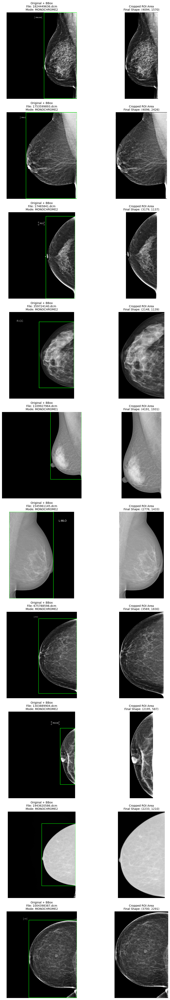

In [31]:
import os
import glob
import random
import numpy as np
import cv2
import pydicom
import matplotlib.pyplot as plt

# ==========================================
# 1. Your Preprocessing Pipeline Functions
# ==========================================

def normalizer(image, photometric):
    image = image.astype(np.float32)
    if photometric == 'MONOCHROME1':
        image = 255 - image
    image_min, image_max = np.min(image), np.max(image)
    if image_max - image_min > 0:
        image = (image - image_min) / (image_max - image_min) * 255.0
    else:
        image = np.zeros_like(image)
    return image.astype(np.uint8)
    
def get_anatomy_bbox(image, threshold_value=15):
    """
    Finds the bounding box of the main anatomy in a normalized 8-bit image
    by isolating the largest connected component.
    
    Returns:
        bbox (list): [x_min, y_min, x_max, y_max]
    """
    # 1. Light Gaussian blur to smooth out internal textures and noise
    blurred = cv2.GaussianBlur(image, (5, 5), 0)
    
    # 2. Binarize the image
    _, binary_mask = cv2.threshold(blurred, threshold_value, 255, cv2.THRESH_BINARY)
    
    # 3. Clean up the mask using Morphological Closing
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (15, 15))
    closed_mask = cv2.morphologyEx(binary_mask, cv2.MORPH_CLOSE, kernel)
    
    # 4. Find all external contours in the mask
    contours, _ = cv2.findContours(closed_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    
    # Fallback if image is completely black or no contours found
    if not contours:
        h, w = image.shape
        return [0, 0, w, h]
        
    # 5. Extract the largest contour by area (this drops small text/markers)
    largest_contour = max(contours, key=cv2.contourArea)
    
    # 6. Get the standard bounding box of that contour
    x_min, y_min, w, h = cv2.boundingRect(largest_contour)
    x_max = x_min + w
    y_max = y_min + h
    
    return [x_min, y_min, x_max, y_max]

def crop_to_bbox(image, bbox, padding=0):
    """
    Crops the image to the bounding box, with optional padding.
    """
    x_min, y_min, x_max, y_max = bbox
    h, w = image.shape
    
    # Add padding but ensure we don't go outside image dimensions
    x_min = max(0, x_min - padding)
    y_min = max(0, y_min - padding)
    x_max = min(w, x_max + padding)
    y_max = min(h, y_max + padding)
    
    return image[y_min:y_max, x_min:x_max]


# ==========================================
# 2. Sampling and Visualization Core
# ==========================================

def sanity_check_roi_pipeline(num_samples=10, padding=20):
    """
    Finds random DICOM files from base_path, applies the pipeline, 
    and outputs side-by-side plots for sanity check.
    """
    # Look for any .dcm file recursively under the given directory
    all_dcm_files =sorted(glob.glob("/kaggle/input/competitions/rsna-breast-cancer-detection/train_images/*/*.dcm"))
    # Dynamically select random samples
    samples_to_take = min(num_samples, len(all_dcm_files))
    sampled_files = random.sample(all_dcm_files, samples_to_take)
    
    # Initialize the plot layout (Rows = Images, Cols = Before vs After)
    fig, axes = plt.subplots(10, 2, figsize=(12, 5 * samples_to_take))
    
    # Fix dimensions if only 1 sample is taken
    if samples_to_take == 1:
        axes = np.expand_dims(axes, axis=0)

    for idx, file_path in enumerate(sampled_files):
        try:
            # 1. Load raw DICOM data and pixel array
            dicom_data = pydicom.dcmread(file_path)
            raw_image = dicom_data.pixel_array
            
            # Extract Photometric Interpretation safely (default to MONOCHROME2 if missing)
            photometric = getattr(dicom_data, "PhotometricInterpretation", "MONOCHROME2")
            
            # 2. Run your pipeline
            normalized_img = normalizer(raw_image, photometric)
            bbox = get_anatomy_bbox(normalized_img)
            cropped_img = crop_to_bbox(normalized_img, bbox, padding=padding)
            
            # 3. Create a color canvas of the original image to draw a colored box
            vis_original = cv2.cvtColor(normalized_img, cv2.COLOR_GRAY2RGB)
            x_min, y_min, x_max, y_max = bbox
            
            # Dynamically scale box thickness relative to image height
            box_thickness = max(2, int(vis_original.shape[0] / 300))
            cv2.rectangle(vis_original, (x_min, y_min), (x_max, y_max), (0, 255, 0), box_thickness)
            
            # 4. Render Plots
            file_name = os.path.basename(file_path)
            
            # Column 1: Normalized original image + green bounding box
            axes[idx, 0].imshow(vis_original)
            axes[idx, 0].set_title(f"Original + BBox\nFile: {file_name}\nMode: {photometric}", fontsize=10)
            axes[idx, 0].axis('off')
            
            # Column 2: Final cropped ROI
            axes[idx, 1].imshow(cropped_img, cmap='gray')
            axes[idx, 1].set_title(f"Cropped ROI Area\nFinal Shape: {cropped_img.shape}", fontsize=10)
            axes[idx, 1].axis('off')
            
        except Exception as e:
            print(f"❌ Error processing file {file_path}: {e}")
            axes[idx, 0].text(0.5, 0.5, f"Error reading file:\n{os.path.basename(file_path)}", 
                              ha='center', va='center', color='red')
            axes[idx, 0].axis('off')
            axes[idx, 1].axis('off')
            
    plt.tight_layout()
    plt.show()

sanity_check_roi_pipeline( num_samples=10, padding=15)

length of df : 54706
target value_count(cancer) : cancer
0    53548
1     1158
Name: count, dtype: int64


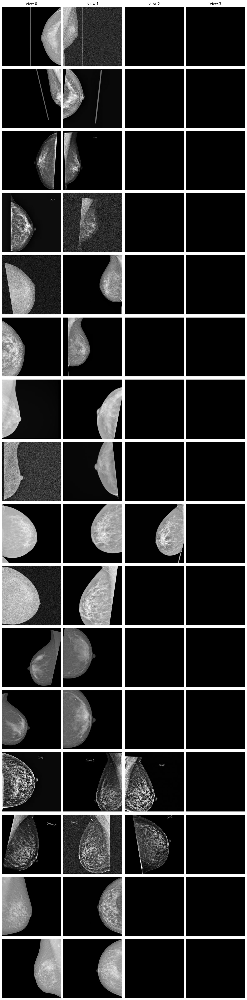

In [32]:

import warnings
warnings.filterwarnings("ignore")
import os
import sys
import json
from glob import glob
import random
import collections
import time
import re
from typing import Optional
import math

import numpy as np
import pandas as pd
import pydicom
try:
    import dicomsdl
except ImportError:
    dicomsdl = None
from pydicom.pixel_data_handlers.util import apply_voi_lut
import cv2
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_auc_score
from tqdm import tqdm
import albumentations as A
from albumentations.pytorch import ToTensorV2
import timm

import torch
from torch import nn
from torch.utils import data as torch_data
from sklearn import model_selection as sk_model_selection
from torch.nn import functional as torch_functional
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torch.optim as optim
from torch.optim.lr_scheduler import ReduceLROnPlateau
from torch.cuda.amp import autocast, GradScaler
from torch.optim.lr_scheduler import LinearLR, CosineAnnealingLR, SequentialLR
from torch.utils.data.distributed import DistributedSampler

# import torch_xla.core.xla_model as xm
# import torch_xla.distributed.parallel_loader as pl
# import torch_xla.distributed.xla_multiprocessing as xmp
# import torch_xla.runtime as xr
# import torch_xla.debug.metrics as met


from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.model_selection import train_test_split
from IPython.display import clear_output
clear_output()

# -----------------------------------------
#              Global Values
# -----------------------------------------

IMG_SIZE = 1024 
BATCH_SIZE = 16
LR = 5e-4
MAX_IMAGES = 4 # Number of views per laterlaity per patient
NEG_TO_POS_RATIO = 5
# -----------------------------------------
#              Augmentation
# -----------------------------------------
def group_views_by_patient_laterality(df):
    """
    Groups per-image rows into one row per (patient_id, laterality), with
    image_id/view collected into lists — the shape MammoDataset expects
    ('row['image_id']' must be a list, not a scalar id).
    """
    return df.groupby(['patient_id', 'laterality']).agg({
        'image_id': list,
        'view': list,
        'cancer': 'max'
    }).reset_index()
train_transforms = A.Compose([
    A.HorizontalFlip(p=0.5),
    A.ShiftScaleRotate(
        shift_limit=0.1, scale_limit=0.15, rotate_limit=15,
        border_mode=0, value=0, p=0.5
    ),
    A.RandomBrightnessContrast(brightness_limit=0.1, contrast_limit=0.1, p=0.5),
    A.RandomGamma(gamma_limit=(95, 105), p=0.2),
    A.GaussNoise(var_limit=(1, 7), p=0.2),
    A.CLAHE(clip_limit=2.0, tile_grid_size=(8, 8), p=0.4),
    A.Resize(IMG_SIZE, IMG_SIZE),  # now just a defensive no-op
    A.Normalize(mean=[0.485], std=[0.229]),
    ToTensorV2(),
])

valid_transforms = A.Compose([
    A.Resize(IMG_SIZE, IMG_SIZE),
    A.Normalize(mean=[0.485], std=[0.229]),
    ToTensorV2(),
])


# -----------------------------------------
#              Preprocessing
# -----------------------------------------
def normalizer(image, photometric):
    image = image.astype(np.float32)
    if photometric == 'MONOCHROME1':
        image = 255 - image
    image_min, image_max = np.min(image), np.max(image)
    if image_max - image_min > 0:
        image = (image - image_min) / (image_max - image_min) * 255.0
    else:
        image = np.zeros_like(image)
    return image.astype(np.uint8)
    
def get_anatomy_bbox(image, threshold_value=15):
    """
    Finds the bounding box of the main anatomy in a normalized 8-bit image
    by isolating the largest connected component.
    
    Returns:
        bbox (list): [x_min, y_min, x_max, y_max]
    """
    # 1. Light Gaussian blur to smooth out internal textures and noise
    blurred = cv2.GaussianBlur(image, (5, 5), 0)
    
    # 2. Binarize the image
    # Any pixel brighter than threshold_value becomes 255 (white), rest become 0 (black)
    _, binary_mask = cv2.threshold(blurred, threshold_value, 255, cv2.THRESH_BINARY)
    
    # 3. Clean up the mask using Morphological Closing
    # This fills in small holes inside the anatomy (like dark spots in lungs or ventricles)
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (15, 15))
    closed_mask = cv2.morphologyEx(binary_mask, cv2.MORPH_CLOSE, kernel)
    
    # 4. Find all external contours in the mask
    contours, _ = cv2.findContours(closed_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    
    # Fallback if image is completely black or no contours found
    if not contours:
        h, w = image.shape
        return [0, 0, w, h]
        
    # 5. Extract the largest contour by area (this drops small text/markers)
    largest_contour = max(contours, key=cv2.contourArea)
    
    # 6. Get the standard bounding box of that contour
    x_min, y_min, w, h = cv2.boundingRect(largest_contour)
    x_max = x_min + w
    y_max = y_min + h
    
    return [x_min, y_min, x_max, y_max]

def crop_to_bbox(image, bbox, padding=0):
    """
    Crops the image to the bounding box, with optional padding.
    """
    x_min, y_min, x_max, y_max = bbox
    h, w = image.shape
    
    # Add padding but ensure we don't go outside image dimensions
    x_min = max(0, x_min - padding)
    y_min = max(0, y_min - padding)
    x_max = min(w, x_max + padding)
    y_max = min(h, y_max + padding)
    
    return image[y_min:y_max, x_min:x_max]


def get_roi_random_crop(image, bbox, crop_h, crop_w, roi_padding=10, random_position=True):
    """
    Crops a fixed-size (crop_h x crop_w) window that fully contains the
    (padded) ROI bbox, without ever stretching width/height independently.

    If the ROI is bigger than the target crop, the WHOLE image is downscaled
    by a single uniform factor first (just enough for the ROI to fit) —
    unlike crop-to-bbox + A.Resize, this preserves aspect ratio.

    random_position=True places the window randomly among all valid
    positions (train). random_position=False centers it on the ROI
    (val/test — keeps eval metrics reproducible across epochs).
    """

    h, w = image.shape[:2]
    x_min, y_min, x_max, y_max = bbox

    x_min = max(0, x_min - roi_padding)
    y_min = max(0, y_min - roi_padding)
    x_max = min(w, x_max + roi_padding)
    y_max = min(h, y_max + roi_padding)
    bbox_w, bbox_h = x_max - x_min, y_max - y_min

    if bbox_w > crop_w or bbox_h > crop_h:
        scale = min(crop_w / bbox_w, crop_h / bbox_h)
        new_w, new_h = max(1, round(w * scale)), max(1, round(h * scale))
        image = cv2.resize(image, (new_w, new_h), interpolation=cv2.INTER_AREA)
        x_min, y_min, x_max, y_max = [v * scale for v in (x_min, y_min, x_max, y_max)]
        h, w = new_h, new_w
        bbox_w, bbox_h = x_max - x_min, y_max - y_min

    pad_b, pad_r = max(0, crop_h - h), max(0, crop_w - w)
    if pad_b or pad_r:
        image = cv2.copyMakeBorder(image, 0, pad_b, 0, pad_r, cv2.BORDER_CONSTANT, value=0)
        h, w = image.shape[:2]

    x_lo, x_hi = max(0, x_max - crop_w), min(x_min, w - crop_w)
    y_lo, y_hi = max(0, y_max - crop_h), min(y_min, h - crop_h)
    x_lo, x_hi = math.ceil(x_lo), math.floor(x_hi)
    y_lo, y_hi = math.ceil(y_lo), math.floor(y_hi)
    x_hi, y_hi = max(x_hi, x_lo), max(y_hi, y_lo)

    x_lo, x_hi = min(x_lo, w - crop_w), min(x_hi, w - crop_w)
    y_lo, y_hi = min(y_lo, h - crop_h), min(y_hi, h - crop_h)
    x_lo, y_lo = max(x_lo, 0), max(y_lo, 0)

    if random_position:
        x_start, y_start = random.randint(x_lo, x_hi), random.randint(y_lo, y_hi)
    else:
        x_start, y_start = (x_lo + x_hi) // 2, (y_lo + y_hi) // 2

    cropped = image[y_start:y_start + crop_h, x_start:x_start + crop_w]

    ch, cw = cropped.shape[:2]
    if ch != crop_h or cw != crop_w:
        cropped = cv2.copyMakeBorder(
            cropped, 0, max(0, crop_h - ch), 0, max(0, crop_w - cw),
            cv2.BORDER_CONSTANT, value=0
        )[:crop_h, :crop_w]

    return cropped

# -----------------------------------------
#              Dataset
# -----------------------------------------

class MammoDataset(Dataset): 
    def __init__(self, df: pd.DataFrame, transforms: A.Compose = None, split: str = 'train', 
                 max_images: int = MAX_IMAGES, random_crop_roi: bool = True):
        """
        Args:
            df (pd.DataFrame): Pre-aggregated dataframe containing grouped image_ids.
            transforms (A.Compose): Albumentations transformation pipeline.
            split (str): 'train' for training/validation, 'test' for test inference.
            max_images (int): Fixed number of views to return per breast side (pads or truncates).
        """
        self.transforms = transforms
        self.split = split
        self.max_images = max_images
        self.random_crop_roi = random_crop_roi 
        
        self.img_dir = (
            "/kaggle/input/competitions/rsna-breast-cancer-detection/train_images"
            if split == 'train' else 
            "/kaggle/input/competitions/rsna-breast-cancer-detection/test_images"
        )
        
        # CRITICAL SPEEDUP: Convert DataFrame into a native Python list of dicts.
        # This completely avoids Pandas .iloc overhead inside __getitem__.
        self.records = df.to_dict(orient='records')

    def __len__(self):
        return len(self.records)

    def __getitem__(self, idx):
        row = self.records[idx]
        patient_id = row['patient_id']
        image_ids = row['image_id'] # This is now a list, e.g., ['123', '456']
        
        images = []
        
        # Process a fixed number of views per breast side
        for i in range(self.max_images):
            if i < len(image_ids):
                img_id = image_ids[i]
                img_path = os.path.join(self.img_dir, str(patient_id), f"{img_id}.dcm")
                
                # Fast DICOM reading using dicomsdl with pydicom fallback
                try:
                    dcm = dicomsdl.open(img_path)
                    image = dcm.pixelData()
                    photometric = dcm.PhotometricInterpretation
                except Exception:
                    try:
                        dcm = pydicom.dcmread(img_path)
                        image = dcm.pixel_array
                        photometric = getattr(dcm, 'PhotometricInterpretation', 'MONOCHROME2')
                    except FileNotFoundError:
                        print(f'FileNotFoundError: {img_path}')
                        raise

                image = normalizer(image, photometric)
                bbox = get_anatomy_bbox(image, threshold_value=15)
                tight_image = get_roi_random_crop(
                    image, bbox, crop_h=IMG_SIZE, crop_w=IMG_SIZE,
                    roi_padding=10, random_position=self.random_crop_roi
                )
                
                # Apply Augmentations (A.CLAHE requires uint8 CV_8UC1)
                if self.transforms:
                    augmented = self.transforms(image=tight_image)
                    image = augmented['image']
                    
                    # Ensure output is a tensor (1, H, W)
                    if not isinstance(image, torch.Tensor):
                        image = torch.tensor(image, dtype=torch.float32) / 255.0
                        if image.ndim == 2:
                            image = image.unsqueeze(0)  
                else:
                    image = tight_image.astype(np.float32) / 255.0
                    image = torch.tensor(image, dtype=torch.float32).unsqueeze(0)  
            else:
                # Padding strategy: Use a zero tensor matching the size of the first view
                if len(images) > 0:
                    image = torch.zeros_like(images[0])
                else:
                    # Fallback default dimension if breast has absolutely no images (rare)
                    image = torch.zeros((1, 1024, 1024), dtype=torch.float32)  
            
            images.append(image)
            
        # Stack multiple views together -> Shape: (max_images, Channels, Height, Width)
        images_tensor = torch.cat(images, dim=0)
        
        # Compile Metadata and Output Package
        data_packet = {
            'image': images_tensor,
            'patient_id': patient_id,
            'laterality': row['laterality']
        }

        # Extract remaining metadata dynamically
        exclude_cols = {'patient_id', 'image_id', 'biopsy', 'invasive', 'density', 'laterality',
                        'BIRADS', 'difficult_negative_case', 'cancer', 'prediction_id', 'view' , }
        metadata = [float(row[k]) for k in row.keys() if k not in exclude_cols and pd.notna(row[k])]
        
        # if metadata:
        #     data_packet['metadata'] = torch.tensor(metadata, dtype=torch.float32)

        # Ground truth/Prediction IDs
        if self.split == 'train':  
            data_packet['target'] = torch.tensor(row['cancer'], dtype=torch.float32)
        else:
            data_packet['prediction_id'] = str(row.get('prediction_id', f"{patient_id}_{row['laterality']}"))

        return data_packet

 
train_df = pd.read_csv('/kaggle/input/competitions/rsna-breast-cancer-detection/train.csv')
train_df['patient_id'] = train_df['patient_id'].astype(str)
train_df['image_id'] = train_df['image_id'].astype(str)
print(f"length of df : {len(train_df)}")
print(f"target value_count(cancer) : {train_df['cancer'].value_counts()}")
train_df = group_views_by_patient_laterality(train_df)

train_ds = MammoDataset(train_df, transforms=train_transforms, split='train', random_crop_roi=True)
        
train_loader = DataLoader(
    dataset=train_ds, batch_size=16, num_workers=4,drop_last=True) 

def show_batch(pack, n_samples=16):
    mean, std = 0.485, 0.229
    images = pack['image'][:n_samples]      # (n_samples, max_images, H, W)
    n_views = images.shape[1]

    fig, axes = plt.subplots(n_samples, n_views, figsize=(3*n_views, 3*n_samples))
    if n_samples == 1:
        axes = axes[None, :]

    for row in range(n_samples):
        for col in range(n_views):
            # print(f'n_views {n_views}')
            
            img = images[row, col].numpy()
            img = np.clip(img * std + mean, 0, 1)   # undo A.Normalize
            axes[row, col].imshow(img, cmap='gray')
            axes[row, col].axis('off')
            if row == 0:
                axes[row, col].set_title(f'view {col}')
    plt.tight_layout()
    plt.show()

pack = next(iter(train_loader))
show_batch(pack, n_samples=16)